# 05b. 업무지구 접근성과 아파트 특성(면적·연식·층)의 크기 비교

- **질문:** 업무지구까지의 통근시간은 면적·연식·층 같은 아파트 특성과 비교해 ㎡당 가격과 얼마나 크게 함께 움직이는가?
- **배경:** 사용자 요청으로 추가한 분석이다. 원래 계획(`reviews/재분석_실행계획_2026-11-23.md`)에는 없었고, 메인 세션이 작성했다. Codex 검사는 받지 않았다. 계획 8단계(공통 기준의 요인 비교)를 05 범위에서 먼저 해 본 것이다.
- **방법(교재 5장 다중회귀를 변형)**
  - 거래 하나를 한 행으로 쓴다. 기간은 2024-01~2026-09이고, 일괄 거래를 뺀 기본 표본이다. 분석 동은 05 주결과와 같은 255개 동이다(거래 30건 이상, 통근시간·교통 자료가 있는 동).
  - 회귀식: log(㎡당 가격) ~ 면적·연식·층 구간 + 최단 통근시간 + log 역까지 거리 + 반경 500m 버스정류소 수 + log 단지 세대수(동 중앙값) + log(1+입시·보습 학원 수) + 구 고정효과 + 연월 고정효과
  - 동 단위 변수가 섞여 있어 표준오차는 동 클러스터로 계산한다.
- **비교 지표: p값으로는 순위를 매기지 않는다.** 18만 건이라 거의 모든 변수의 p값이 0에 가깝고, p값은 크기를 뜻하지 않기 때문이다. 대신 두 가지로 비교한다.
  1. **같은 잣대의 가격 차이:** 각 변수가 표본의 25% 분위 값에서 75% 분위 값으로 바뀔 때, 다른 변수를 고정한 상태의 ㎡당 가격 차이(%)다. 구간 변수(면적·연식·층)는 25%·75% 분위 값이 속한 구간의 계수 차이로 계산한다. 구간 사이 최대 차이도 함께 적는다.
  2. **설명력 기여:** 변수 묶음 하나를 뺐을 때 구 안·같은 달 안 설명력(within R²)이 얼마나 줄어드는지(ΔR²)다.
- **주의:** 통근·교통·교육은 동 단위 값이라 같은 동 안에서는 변하지 않는다. 구 고정효과를 넣었기 때문에 같은 구 안의 동 사이 차이만 쓴다. 반면 면적·연식·층은 단지와 거래마다 달라진다. 두 묶음은 변동의 단위가 달라서, 이 비교는 "이 표본에서 각 묶음이 가격 차이와 얼마나 함께 움직였는가"를 보여 줄 뿐 인과적 중요도가 아니다.

**코드 수준:** 계수(크기)만 필요한 단계는 pandas 평균 빼기와 `LinearRegression`으로 쓴 쉬운 함수(`ru.easy_index`, `ru.easy_dong_level` 등)를 쓴다. 원래 함수와 값이 같다(차이 1e-8 이하). 표준오차·검정·부트스트랩이 필요한 단계는 기존 재검증 코드를 그대로 쓴다. 이 노트북에서 쉬운 버전으로 바꾼 곳: 요인 묶음 제외 설명력(ΔR², 구·연월 더미 + `LinearRegression`). 흔한 차이의 신뢰구간(동 클러스터 표준오차)은 원래 코드를 쓴다.


In [1]:
import os
import sys
from pathlib import Path


def _find_root():
    env = os.environ.get("REANALYSIS_ROOT")
    if env:
        return Path(env).resolve()
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "AGENTS.md").exists():
            return p
    raise FileNotFoundError("AGENTS.md가 있는 프로젝트 루트를 찾지 못했습니다")


ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src" / "재검증"))
import warnings
warnings.filterwarnings("ignore")
import json
import numpy as np
import pandas as pd
import reanalysis_utils as ru
from scipy import stats

SEED = ru.SEED
OUT = ru.out_dir(ROOT, "05b")
plt = ru.set_korean_font()

## 1. 표본 만들기

05 주결과와 같은 255개 동을 고르고, 그 동의 2024-01~2026-09 거래에 동 특징을 붙인다. 조인할 때마다 행 수를 확인한다.

In [2]:
feat = pd.read_parquet(ROOT / "outputs" / "재검증" / "00_정제" / "dong_features.parquet")
cols = ["row_id", "dong_id", "gu", "contract_ym", "log_ppa", "area_m2", "age", "floor",
        "area_bin", "age_bin", "floor_bin", "in_base_nobulk"]
tx = ru.load_tx(ROOT, columns=cols)
PER = ru.ym_range("2024-01", "2026-09")
d = tx[tx["in_base_nobulk"] & tx["contract_ym"].isin(PER) & (tx["floor_bin"] != "B")].reset_index(drop=True)

feat = feat.assign(log_subway=np.log(feat["subway_dist_m"]), log_hh=np.log(feat["apt_households_median"]),
                   log_acad=np.log1p(feat["acad_exam"]))
ntx = d.groupby("dong_id").size().rename("n_tx")
feat = feat.merge(ntx, left_on="dong_id", right_index=True, how="left")
DONGVARS = ["commute_min", "commute_gwanghwamun", "commute_gangnam", "commute_yeouido",
            "log_subway", "bus_n_500m", "log_hh", "log_acad"]
ok = (feat["n_tx"].fillna(0) >= 30) & ~feat["commute_missing"] & feat[["log_subway", "bus_n_500m", "log_hh"]].notna().all(axis=1)
dongs = feat.loc[ok, ["dong_id"] + DONGVARS]
n_before = len(d)
s = d.merge(dongs, on="dong_id", how="inner", validate="many_to_one")
assert len(s) <= n_before
s = s.dropna(subset=DONGVARS + ["log_ppa"]).reset_index(drop=True)
pd.Series({"기간 내 거래(지하층 제외)": n_before, "분석 동 수": int(ok.sum()),
           "분석 거래 수": len(s), "분석 동 중 학원 결측": int(dongs["log_acad"].isna().sum())}).to_frame("값")

,값
기간 내 거래(지하층 제외),181853
분석 동 수,255
분석 거래 수,180961
분석 동 중 학원 결측,0


## 2. 전체 회귀

면적·연식·층은 05·03과 같은 기준 구간(60~85㎡, 10~14년, 6~10층)을 뺀 더미로 넣는다.

In [3]:
REFS = {"area_bin": "060-085", "age_bin": "10-14", "floor_bin": "06-10"}
D = ru.dummies(s, REFS)
GROUPS = {
    "면적": [c for c in D.columns if c.startswith("area_bin=")],
    "연식": [c for c in D.columns if c.startswith("age_bin=")],
    "층": [c for c in D.columns if c.startswith("floor_bin=")],
    "업무지구 통근시간": ["commute_min"],
    "역·버스 접근성": ["log_subway", "bus_n_500m"],
    "단지 규모": ["log_hh"],
    "교육(학원)": ["log_acad"],
}
X = pd.concat([D, s[["commute_min", "log_subway", "bus_n_500m", "log_hh", "log_acad"]]], axis=1)
FE = [s["gu"].to_numpy(), s["contract_ym"].to_numpy()]
CL = s["dong_id"].to_numpy()
res = ru.fe_ols(s["log_ppa"], X, FE, clusters=CL)
ct = ru.coef_table(res)
print(f"n={res['n']:,}, 동 클러스터 {res['n_clusters']}개, within R²={res['r2_within']:.3f}")
ct[ct["term"].isin(["commute_min", "log_subway", "bus_n_500m", "log_hh", "log_acad"])].round(4)

n=180,961, 동 클러스터 255개, within R²=0.383


,term,coef,se,t,p_value,ci_low,ci_high
19,commute_min,-0.0087,0.0015,-5.6949,0.0000,-0.0117,-0.0057
20,log_subway,-0.0960,0.0379,-2.5347,0.0119,-0.1706,-0.0214
21,bus_n_500m,-0.0053,0.0019,-2.7347,0.0067,-0.0091,-0.0015
22,log_hh,0.2227,0.0285,7.8137,0.0000,0.1665,0.2788
23,log_acad,0.0378,0.0114,3.3290,0.0010,0.0154,0.0602


## 3. 표 ①: 같은 잣대로 본 가격 차이

각 변수를 표본의 25% 분위 값에서 75% 분위 값으로 바꿀 때의 ㎡당 가격 차이(%)와 95% 신뢰구간이다.
- 연속 변수: 100×(exp(b·(p75−p25))−1)
- 구간 변수: p25·p75 값이 속한 두 구간의 계수 차이를 같은 식으로 바꾼다. 기준 구간의 계수는 0이다.
- "구간 사이 최대 차이"는 가장 높은 구간과 가장 낮은 구간의 차이다(구간 변수만).

업무지구 3곳은 최단 통근시간 대신 3곳을 함께 넣은 별도 회귀에서 계산했다(나머지 변수는 같다).

In [4]:
b, V = res["beta"], res["vcov"]
tq = stats.t.ppf(0.975, res["dof"])


def lin_pct(w: pd.Series, bb=b, VV=V):
    w = w.reindex(bb.index).fillna(0.0)
    est = float(w @ bb)
    se = float(np.sqrt(w @ VV @ w))
    f = lambda x: 100 * (np.exp(x) - 1)
    return f(est), f(est - tq * se), f(est + tq * se)


def bin_of(var, value):
    edges = {"area_bin": [(0, 40, "000-040"), (40, 60, "040-060"), (60, 85, "060-085"), (85, 102, "085-102"),
                          (102, 135, "102-135"), (135, 1e9, "135+")],
             "age_bin": [(0, 5, "00-04"), (5, 10, "05-09"), (10, 15, "10-14"), (15, 20, "15-19"), (20, 25, "20-24"),
                         (25, 30, "25-29"), (30, 35, "30-34"), (35, 1e9, "35+")],
             "floor_bin": [(1, 2, "01"), (2, 3, "02"), (3, 6, "03-05"), (6, 11, "06-10"), (11, 16, "11-15"),
                           (16, 21, "16-20"), (21, 31, "21-30"), (31, 1e9, "31+")]}[var]
    for lo, hi, lab in edges:
        if lo <= value < hi:
            return lab
    raise ValueError((var, value))


rows = []
raw = {"area_bin": ("area_m2", "면적", "㎡"), "age_bin": ("age", "연식", "년"), "floor_bin": ("floor", "층", "층")}
for var, (col, label, unit) in raw.items():
    p25, p75 = s[col].quantile([0.25, 0.75])
    b25, b75 = bin_of(var, p25), bin_of(var, p75)
    w = pd.Series(0.0, index=b.index)
    if b75 != REFS[var]:
        w[f"{var}={b75}"] += 1
    if b25 != REFS[var]:
        w[f"{var}={b25}"] -= 1
    est, lo, hi = lin_pct(w)
    coefs = pd.Series({REFS[var]: 0.0, **{c.split("=")[1]: b[c] for c in GROUPS[label]}})
    rows.append({"변수": label, "p25": p25, "p75": p75, "단위": unit, "비교": f"{b25} → {b75} 구간",
                 "가격 차이(%)": est, "CI 하한": lo, "CI 상한": hi,
                 "구간 사이 최대 차이(%)": 100 * (np.exp(coefs.max() - coefs.min()) - 1)})

cont = {"commute_min": ("최단 업무지구 통근시간", "분"), "log_subway": ("가장 가까운 역까지 거리", "m"),
        "bus_n_500m": ("반경 500m 버스정류소", "개"), "log_hh": ("단지 세대수(동 중앙값)", "세대"),
        "log_acad": ("입시·보습 학원 수", "개")}
back = {"log_subway": np.exp, "log_hh": np.exp, "log_acad": lambda x: np.expm1(x)}
for col, (label, unit) in cont.items():
    p25, p75 = s[col].quantile([0.25, 0.75])
    w = pd.Series(0.0, index=b.index); w[col] = p75 - p25
    est, lo, hi = lin_pct(w)
    f = back.get(col, lambda x: x)
    rows.append({"변수": label, "p25": f(p25), "p75": f(p75), "단위": unit, "비교": "p25 → p75",
                 "가격 차이(%)": est, "CI 하한": lo, "CI 상한": hi, "구간 사이 최대 차이(%)": np.nan})

# 업무지구 3곳 동시 회귀
X3 = pd.concat([D, s[["commute_gwanghwamun", "commute_gangnam", "commute_yeouido",
                      "log_subway", "bus_n_500m", "log_hh", "log_acad"]]], axis=1)
res3 = ru.fe_ols(s["log_ppa"], X3, FE, clusters=CL)
tq3 = stats.t.ppf(0.975, res3["dof"])
for col, label in [("commute_gangnam", "강남까지 통근시간(3곳 동시)"), ("commute_yeouido", "여의도까지 통근시간(3곳 동시)"),
                   ("commute_gwanghwamun", "광화문까지 통근시간(3곳 동시)")]:
    p25, p75 = s[col].quantile([0.25, 0.75])
    w = pd.Series(0.0, index=res3["beta"].index); w[col] = p75 - p25
    est = float(w @ res3["beta"]); se = float(np.sqrt(w @ res3["vcov"] @ w))
    f = lambda x: 100 * (np.exp(x) - 1)
    rows.append({"변수": label, "p25": p25, "p75": p75, "단위": "분", "비교": "p25 → p75",
                 "가격 차이(%)": f(est), "CI 하한": f(est - tq3 * se), "CI 상한": f(est + tq3 * se),
                 "구간 사이 최대 차이(%)": np.nan})

t1 = pd.DataFrame(rows)
t1["|차이|"] = t1["가격 차이(%)"].abs()
t1["유의(95% CI가 0 미포함)"] = (t1["CI 하한"] > 0) | (t1["CI 상한"] < 0)
t1 = t1.sort_values("|차이|", ascending=False).drop(columns="|차이|").reset_index(drop=True)
t1.round(2)

,변수,p25,p75,단위,비교,가격 차이(%),CI 하한,CI 상한,구간 사이 최대 차이(%),유의(95% CI가 0 미포함)
0,최단 업무지구 통근시간,23.67,41.87,분,p25 → p75,-14.66,-19.21,-9.85,NaN,True
1,면적,59.78,84.96,㎡,040-060 → 060-085 구간,-12.38,-14.03,-10.70,31.04,True
2,연식,14.00,30.00,년,10-14 → 30-34 구간,-12.32,-18.13,-6.10,47.15,True
3,여의도까지 통근시간(3곳 동시),30.82,52.45,분,p25 → p75,-10.76,-17.57,-3.39,NaN,True
4,단지 세대수(동 중앙값),328.00,508.00,세대,p25 → p75,10.23,7.56,12.97,NaN,True
5,강남까지 통근시간(3곳 동시),37.10,57.97,분,p25 → p75,-8.45,-14.53,-1.94,NaN,True
6,층,5.00,13.00,층,03-05 → 11-15 구간,7.33,5.88,8.81,37.22,True
7,광화문까지 통근시간(3곳 동시),36.90,51.52,분,p25 → p75,-6.24,-12.35,0.29,NaN,False
8,입시·보습 학원 수,36.00,135.00,개,p25 → p75,5.04,2.03,8.14,NaN,True
9,반경 500m 버스정류소,17.00,25.00,개,p25 → p75,-4.14,-7.01,-1.17,NaN,True


표 ①을 읽는 법은 다음과 같다.
- "가격 차이(%)"는 다른 변수와 구·연월을 고정했을 때, 그 변수만 표본의 하위 25% 값에서 상위 25% 값으로 바뀐 거래 사이의 ㎡당 가격 차이다. 음수는 값이 커질수록(예: 통근시간이 길수록) 가격이 낮은 경향이라는 뜻이다.
- 면적·층은 25%·75% 분위가 인접 구간에 있어 이 기준의 차이가 작게 나올 수 있다. 그래서 구간 사이 최대 차이를 옆에 둔다.

## 4. 표 ②: 설명력 기여(묶음 하나를 뺐을 때 within R² 감소)

In [5]:
# within R² = 1 − (전체 모형의 잔차제곱합) / (구·연월 더미만 넣은 모형의 잔차제곱합)
from sklearn.linear_model import LinearRegression
FE_DUM = pd.get_dummies(s[["gu", "contract_ym"]], drop_first=True, dtype=float)


def ssr(Xpart):
    """구·연월 더미와 Xpart로 LinearRegression을 맞추고 잔차제곱합을 돌려준다."""
    Z = pd.concat([FE_DUM, Xpart], axis=1)
    m = LinearRegression().fit(Z, s["log_ppa"])
    return float(((s["log_ppa"] - m.predict(Z)) ** 2).sum())


ssr_fe = ssr(pd.DataFrame(index=s.index))   # 구·연월 더미만
full_r2 = 1 - ssr(X) / ssr_fe
rows2 = []
for g, cs in GROUPS.items():
    r2 = 1 - ssr(X.drop(columns=cs)) / ssr_fe
    rows2.append({"변수 묶음": g, "변수 수": len(cs), "뺀 뒤 within R²": r2,
                  "ΔR²(감소분)": full_r2 - r2,
                  "전체 설명력 중 비중(%)": 100 * (full_r2 - r2) / full_r2})
t2 = pd.DataFrame(rows2).sort_values("ΔR²(감소분)", ascending=False).reset_index(drop=True)
print(f"전체 within R² = {full_r2:.4f} (구·연월 고정효과를 뺀 뒤의 설명력)")
t2.round(4)

전체 within R² = 0.3831 (구·연월 고정효과를 뺀 뒤의 설명력)


,변수 묶음,변수 수,뺀 뒤 within R²,ΔR²(감소분),전체 설명력 중 비중(%)
0,연식,7,0.2497,0.1334,34.8193
1,면적,5,0.3129,0.0702,18.3183
2,단지 규모,1,0.3319,0.0512,13.3683
3,업무지구 통근시간,1,0.3592,0.0239,6.2280
4,층,7,0.3598,0.0233,6.0889
5,역·버스 접근성,2,0.3700,0.0131,3.4088
6,교육(학원),1,0.3744,0.0087,2.2701


표 ②를 읽는 법은 다음과 같다.
- ΔR²는 그 묶음이 다른 묶음과 겹치지 않고 혼자 설명하는 몫이다. 묶음끼리 겹치는 설명력(예: 오래된 단지가 특정 동에 몰린 경우)은 어느 묶음에도 들어가지 않으므로, ΔR²를 모두 더해도 전체 R²보다 작다.
- 구 고정효과가 구 사이 차이를 이미 흡수했기 때문에, 동 단위 변수(통근·교통·교육)의 몫은 같은 구 안 동 사이 차이로만 계산된다.

## 5. 저장과 그림

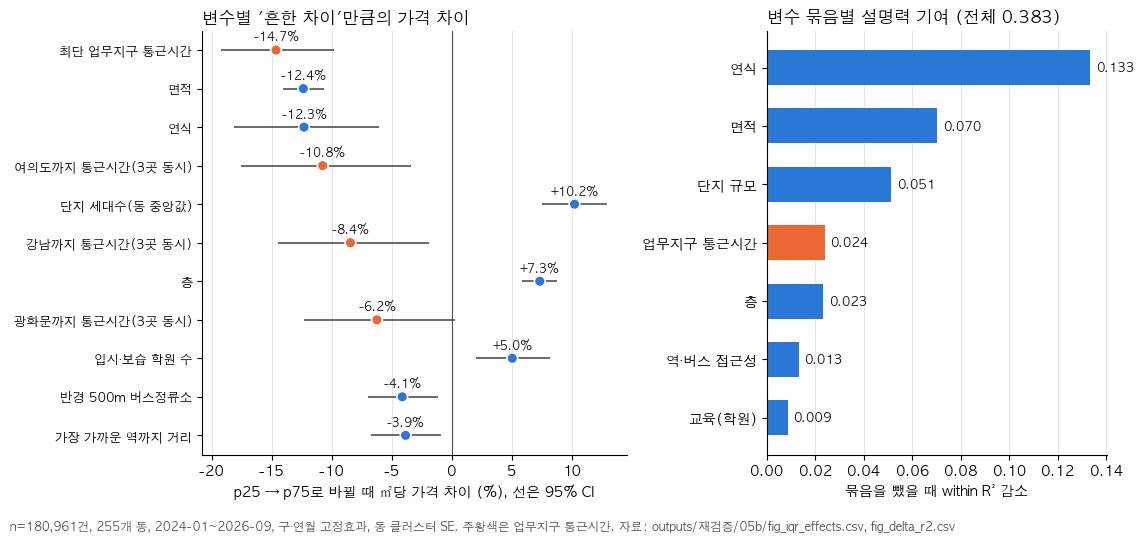

In [6]:
t1_out = t1.rename(columns={"변수": "variable", "p25": "p25", "p75": "p75", "단위": "unit", "비교": "comparison",
                            "가격 차이(%)": "pct_diff", "CI 하한": "ci_low", "CI 상한": "ci_high",
                            "구간 사이 최대 차이(%)": "max_bin_range_pct", "유의(95% CI가 0 미포함)": "ci_excludes_0"})
t2_out = t2.rename(columns={"변수 묶음": "group", "변수 수": "n_vars", "뺀 뒤 within R²": "r2_without",
                            "ΔR²(감소분)": "delta_r2", "전체 설명력 중 비중(%)": "share_pct"})
ru.save_chart_csv(t1_out, OUT, "fig_iqr_effects.csv")
ru.save_chart_csv(t2_out, OUT, "fig_delta_r2.csv")
n, G = res["n"], res["n_clusters"]
srows = []


def add(key, label, value, unit, note, src, claim="통계적 연관"):
    srows.append({"key": key, "label": label, "value": float(value), "unit": unit, "sample_n": int(n),
                  "period": "2024-01~2026-09", "period_start": "2024-01", "period_end": "2026-09",
                  "split_type": "없음", "claim_level": claim, "source_file": src, "note": note})


add("r2_within_full", "전체 회귀 within R²(구·연월 고정효과 제외 후)", full_r2, "R²", f"동 {G}개", "fig_delta_r2.csv")
for _, r in t1_out.iterrows():
    add(f"iqr_{r['variable']}", f"{r['variable']} p25→p75 ㎡당 가격 차이", r["pct_diff"], "%",
        f"95% CI {r['ci_low']:.2f}~{r['ci_high']:.2f}, {r['comparison']}", "fig_iqr_effects.csv")
for _, r in t2_out.iterrows():
    add(f"dr2_{r['group']}", f"{r['group']} 묶음을 뺐을 때 within R² 감소", r["delta_r2"], "R²", "", "fig_delta_r2.csv")
ru.save_summary(srows, OUT)
ru.save_meta({"question": "업무지구 통근시간은 면적·연식·층과 비교해 ㎡당 가격과 얼마나 크게 함께 움직이는가?",
              "method": "거래 단위 log ㎡당 가격 ~ 면적·연식·층 구간 + 동 단위 통근·역·버스·세대수·학원 + 구·연월 FE, 동 클러스터 SE. "
                        "p25→p75 가격 차이, 묶음 제외 ΔR²",
              "textbook_chapters": ["5장 다중회귀"],
              "added_by": "메인 세션(사용자 요청 추가 분석, 계획 밖, Codex 검사 없음)",
              "sample_period": "2024-01~2026-09", "sample_size": {"transactions": int(n), "dongs": int(G)},
              "data_files": ["outputs/재검증/00_정제/transactions.parquet", "outputs/재검증/00_정제/dong_features.parquet"],
              "limitations": ["동 단위 변수와 거래 단위 변수는 변동 단위가 달라 비교가 구조적으로 대칭이 아니다",
                              "구 FE로 동 단위 변수는 구 안 차이만 쓴다",
                              "통근시간 결측 62개 동(도심 집중)과 거래 30건 미만 동 제외",
                              "통근·학원은 현재 시점 자료", "연관이며 인과적 중요도가 아니다"]}, OUT)

# 그림
from IPython.display import Image, display
SER = ["#2a78d6", "#eb6834"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
p = t1.iloc[::-1]
y = np.arange(len(p))
a1.hlines(y, p["CI 하한"], p["CI 상한"], color=INK2, lw=1.2)
a1.scatter(p["가격 차이(%)"], y, s=60, zorder=3, edgecolor="white", lw=1.2,
           color=[SER[1] if "통근" in v else (SER[0] if sig else "#b5b4ad") for v, sig in zip(p["변수"], p["유의(95% CI가 0 미포함)"])])
for yi, v in zip(y, p["가격 차이(%)"]):
    a1.annotate(f"{v:+.1f}%", (v, yi), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8.5, color=INK)
a1.axvline(0, color=INK2, lw=0.8)
a1.set_yticks(y, p["변수"], fontsize=9)
a1.set_xlabel("p25 → p75로 바뀔 때 ㎡당 가격 차이 (%), 선은 95% CI")
a1.set_title("변수별 '흔한 차이'만큼의 가격 차이", loc="left", fontsize=12, color=INK)
q = t2.iloc[::-1]
a2.barh(q["변수 묶음"], q["ΔR²(감소분)"], color=[SER[1] if "통근" in g else SER[0] for g in q["변수 묶음"]], height=0.6)
for yi, v in enumerate(q["ΔR²(감소분)"]):
    a2.annotate(f"{v:.3f}", (v, yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
a2.set_xlabel("묶음을 뺐을 때 within R² 감소")
a2.set_title(f"변수 묶음별 설명력 기여 (전체 {full_r2:.3f})", loc="left", fontsize=12, color=INK)
for ax in (a1, a2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
fig.text(0.01, -0.03, f"n={n:,}건, {G}개 동, 2024-01~2026-09, 구·연월 고정효과, 동 클러스터 SE. 주황색은 업무지구 통근시간. "
         "자료: outputs/재검증/05b/fig_iqr_effects.csv, fig_delta_r2.csv", fontsize=8.5, color=INK2)
fig.tight_layout()
fig.savefig(OUT / "viz_05b_factor_compare.png", dpi=100, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(OUT / "viz_05b_factor_compare.png")))

## 6. 결론과 한계

근거: `outputs/재검증/05b/fig_iqr_effects.csv`(표 ①), `fig_delta_r2.csv`(표 ②). n=180,961건, 255개 동, 2024-01~2026-09, 구·연월 고정효과, 동 클러스터 SE.

**결론(통계적 연관)**
- **같은 잣대(p25→p75)로 보면 업무지구 통근시간이 면적·연식과 비슷한 크기로 가격과 함께 움직였다.**
  - 최단 통근시간: 23.7분 → 41.9분일 때 ㎡당 가격 −14.7%(95% CI −19.2~−9.9)
  - 면적: 40~60㎡ → 60~85㎡ 구간일 때 −12.4%(구간 사이 최대 차이 31%)
  - 연식: 10~14년 → 30~34년 구간일 때 −12.3%(구간 사이 최대 차이 47%)
  - 층: 3~5층 → 11~15층 구간일 때 +7.3%(구간 사이 최대 차이 37%)
- **설명력 기여(ΔR²)로 보면 연식(0.133)과 면적(0.070)이 가장 크고, 통근시간(0.024)은 층(0.023)과 비슷하다.** 전체 within R²는 0.383이다. 통근시간은 동마다 하나의 값이라, 같은 동 안의 가격 차이는 설명할 수 없다. 그래서 "흔한 차이"의 크기는 크지만 설명력 몫은 작게 나온다.
- 업무지구 3곳을 함께 넣으면 거래 단위에서는 여의도(−10.8%)와 강남(−8.4%)이 유의했고, 광화문(−6.2%, CI −12.4~+0.3)은 유의하지 않았다. 동 단위(05)에서는 강남이 가장 컸는데, 거래 단위에서는 여의도가 조금 컸다. 두 결과의 신뢰구간이 겹치므로 강남과 여의도의 순위는 확정할 수 없다.

**한계**
- 동 단위 변수(통근·교통·교육)와 거래 단위 변수(면적·연식·층)는 변동 단위가 달라서, 크기 비교가 대칭이 아니다.
- 구 고정효과 때문에 동 단위 변수는 같은 구 안의 차이만 반영한다. 구 사이 차이까지 보면 통근시간의 몫은 더 커질 수 있다.
- 통근시간 결측 62개 동(도심 집중)과 거래 30건 미만 동은 빠졌다.
- 통근·학원은 현재 시점 자료다.
- 모든 결과는 통계적 연관이고, 인과적 중요도가 아니다. 사용자 요청으로 메인 세션이 추가한 분석이며, Codex 검사는 받지 않았다.